# Noise Reduction Analysis

This notebook analyzes noise reduction between three force signals:
1. **FRaw**: Raw force/torque (baseline, most noisy)
2. **FF_EE**: Filtered force/torque (FRaw filtered with 5Hz low-pass)
3. **predicted_force**: Final predicted force (Quasi-Static + Dynamic from MLP)

**Metrics Calculated:**
- Variance reduction percentage
- High-frequency content reduction (FFT analysis)
- Smoothness improvement (derivative-based)
- RMS deviation from smoothed baseline

**Output:**
- Per-dimension noise reduction percentages
- Summary tables and visualizations


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal
import warnings
warnings.filterwarnings('ignore')

# Load the predictions dataset
data_path = Path('mlp_predictions_dataset.jsonl')

print(f"Loading data from {data_path}...")
data_points = []
with open(data_path, 'r') as f:
    for line in f:
        if line.strip():
            data_points.append(json.loads(line))

print(f"✓ Loaded {len(data_points)} data points")

# Extract the three force signals
FRaw = np.array([dp['FRaw'] for dp in data_points])  # Shape: (N, 6)
FF_EE = np.array([dp['FF_EE'] for dp in data_points])  # Shape: (N, 6)
predicted_force = np.array([dp['predicted_force'] for dp in data_points])  # Shape: (N, 6)

print(f"\nData shapes:")
print(f"  FRaw: {FRaw.shape}")
print(f"  FF_EE: {FF_EE.shape}")
print(f"  predicted_force: {predicted_force.shape}")

# Calculate sampling frequency
timestamps = np.array([dp['timestamp'] for dp in data_points])
mean_freq = 1.0 / np.mean(np.diff(timestamps))
print(f"\nMean sampling frequency: {mean_freq:.2f} Hz")


Loading data from mlp_predictions_dataset.jsonl...
✓ Loaded 48745 data points

Data shapes:
  FRaw: (48745, 6)
  FF_EE: (48745, 6)
  predicted_force: (48745, 6)

Mean sampling frequency: 250.00 Hz


In [2]:
# METRIC 1: Variance Reduction
print("=" * 60)
print("METRIC 1: VARIANCE REDUCTION")
print("=" * 60)

dim_names = ['Fx', 'Fy', 'Fz', 'Mx', 'My', 'Mz']
variance_reduction_results = []

for dim in range(6):
    var_raw = np.var(FRaw[:, dim])
    var_ffee = np.var(FF_EE[:, dim])
    var_pred = np.var(predicted_force[:, dim])
    
    # Calculate noise reduction percentage
    # Noise reduction = (1 - variance_filtered/variance_raw) * 100
    reduction_ffee = (1 - var_ffee / var_raw) * 100
    reduction_pred = (1 - var_pred / var_raw) * 100
    
    variance_reduction_results.append({
        'dimension': dim_names[dim],
        'var_raw': var_raw,
        'var_ffee': var_ffee,
        'var_pred': var_pred,
        'reduction_ffee_%': reduction_ffee,
        'reduction_pred_%': reduction_pred
    })
    
    print(f"\n{dim_names[dim]}:")
    print(f"  Variance - Raw: {var_raw:.6f}, FF_EE: {var_ffee:.6f}, Predicted: {var_pred:.6f}")
    print(f"  Noise Reduction - FF_EE vs Raw: {reduction_ffee:.2f}%")
    print(f"  Noise Reduction - Predicted vs Raw: {reduction_pred:.2f}%")

variance_df = pd.DataFrame(variance_reduction_results)
print(f"\n✓ Variance reduction analysis complete")


METRIC 1: VARIANCE REDUCTION

Fx:
  Variance - Raw: 1.158771, FF_EE: 1.093291, Predicted: 1.094529
  Noise Reduction - FF_EE vs Raw: 5.65%
  Noise Reduction - Predicted vs Raw: 5.54%

Fy:
  Variance - Raw: 1.808042, FF_EE: 1.710396, Predicted: 1.707345
  Noise Reduction - FF_EE vs Raw: 5.40%
  Noise Reduction - Predicted vs Raw: 5.57%

Fz:
  Variance - Raw: 0.125374, FF_EE: 0.061175, Predicted: 0.060442
  Noise Reduction - FF_EE vs Raw: 51.21%
  Noise Reduction - Predicted vs Raw: 51.79%

Mx:
  Variance - Raw: 0.004749, FF_EE: 0.004088, Predicted: 0.004091
  Noise Reduction - FF_EE vs Raw: 13.90%
  Noise Reduction - Predicted vs Raw: 13.86%

My:
  Variance - Raw: 0.003531, FF_EE: 0.003072, Predicted: 0.003068
  Noise Reduction - FF_EE vs Raw: 13.00%
  Noise Reduction - Predicted vs Raw: 13.10%

Mz:
  Variance - Raw: 0.001024, FF_EE: 0.000898, Predicted: 0.000895
  Noise Reduction - FF_EE vs Raw: 12.30%
  Noise Reduction - Predicted vs Raw: 12.55%

✓ Variance reduction analysis complete

In [3]:
# METRIC 2: High-Frequency Content Reduction (FFT Analysis)
print("\n" + "=" * 60)
print("METRIC 2: HIGH-FREQUENCY CONTENT REDUCTION")
print("=" * 60)

# Define high-frequency threshold (e.g., > 5Hz or > 10Hz)
high_freq_threshold = 5.0  # Hz

frequency_reduction_results = []

for dim in range(6):
    # Compute FFT for each signal
    fft_raw = np.fft.fft(FRaw[:, dim])
    fft_ffee = np.fft.fft(FF_EE[:, dim])
    fft_pred = np.fft.fft(predicted_force[:, dim])
    
    # Frequency axis
    freqs = np.fft.fftfreq(len(FRaw[:, dim]), 1/mean_freq)
    
    # Power spectral density
    psd_raw = np.abs(fft_raw)**2
    psd_ffee = np.abs(fft_ffee)**2
    psd_pred = np.abs(fft_pred)**2
    
    # Calculate power in high-frequency band (> threshold)
    high_freq_mask = np.abs(freqs) > high_freq_threshold
    high_freq_power_raw = np.sum(psd_raw[high_freq_mask])
    high_freq_power_ffee = np.sum(psd_ffee[high_freq_mask])
    high_freq_power_pred = np.sum(psd_pred[high_freq_mask])
    
    # Noise reduction percentage
    reduction_ffee = (1 - high_freq_power_ffee / high_freq_power_raw) * 100 if high_freq_power_raw > 0 else 0
    reduction_pred = (1 - high_freq_power_pred / high_freq_power_raw) * 100 if high_freq_power_raw > 0 else 0
    
    frequency_reduction_results.append({
        'dimension': dim_names[dim],
        'high_freq_power_raw': high_freq_power_raw,
        'high_freq_power_ffee': high_freq_power_ffee,
        'high_freq_power_pred': high_freq_power_pred,
        'reduction_ffee_%': reduction_ffee,
        'reduction_pred_%': reduction_pred
    })
    
    print(f"\n{dim_names[dim]} (> {high_freq_threshold} Hz):")
    print(f"  High-Freq Power - Raw: {high_freq_power_raw:.6e}, FF_EE: {high_freq_power_ffee:.6e}, Predicted: {high_freq_power_pred:.6e}")
    print(f"  Noise Reduction - FF_EE vs Raw: {reduction_ffee:.2f}%")
    print(f"  Noise Reduction - Predicted vs Raw: {reduction_pred:.2f}%")

frequency_df = pd.DataFrame(frequency_reduction_results)
print(f"\n✓ High-frequency content analysis complete")



METRIC 2: HIGH-FREQUENCY CONTENT REDUCTION

Fx (> 5.0 Hz):
  High-Freq Power - Raw: 1.462125e+08, FF_EE: 2.536446e+05, Predicted: 5.609544e+04
  Noise Reduction - FF_EE vs Raw: 99.83%
  Noise Reduction - Predicted vs Raw: 99.96%

Fy (> 5.0 Hz):
  High-Freq Power - Raw: 2.176912e+08, FF_EE: 9.464731e+05, Predicted: 5.750822e+05
  Noise Reduction - FF_EE vs Raw: 99.57%
  Noise Reduction - Predicted vs Raw: 99.74%

Fz (> 5.0 Hz):
  High-Freq Power - Raw: 1.478934e+08, FF_EE: 3.043403e+05, Predicted: 5.785568e+04
  Noise Reduction - FF_EE vs Raw: 99.79%
  Noise Reduction - Predicted vs Raw: 99.96%

Mx (> 5.0 Hz):
  High-Freq Power - Raw: 1.532935e+06, FF_EE: 3.182302e+03, Predicted: 1.519065e+03
  Noise Reduction - FF_EE vs Raw: 99.79%
  Noise Reduction - Predicted vs Raw: 99.90%

My (> 5.0 Hz):
  High-Freq Power - Raw: 1.061460e+06, FF_EE: 1.151205e+03, Predicted: 1.489916e+02
  Noise Reduction - FF_EE vs Raw: 99.89%
  Noise Reduction - Predicted vs Raw: 99.99%

Mz (> 5.0 Hz):
  High-Fre

In [4]:
# METRIC 3: Smoothness Improvement (Derivative-based)
print("\n" + "=" * 60)
print("METRIC 3: SMOOTHNESS IMPROVEMENT (Derivative-based)")
print("=" * 60)

smoothness_results = []

for dim in range(6):
    # Calculate first derivative (rate of change)
    deriv_raw = np.diff(FRaw[:, dim])
    deriv_ffee = np.diff(FF_EE[:, dim])
    deriv_pred = np.diff(predicted_force[:, dim])
    
    # Calculate mean absolute derivative (higher = more noisy/jumpy)
    mean_abs_deriv_raw = np.mean(np.abs(deriv_raw))
    mean_abs_deriv_ffee = np.mean(np.abs(deriv_ffee))
    mean_abs_deriv_pred = np.mean(np.abs(deriv_pred))
    
    # Noise reduction = reduction in mean absolute derivative
    reduction_ffee = (1 - mean_abs_deriv_ffee / mean_abs_deriv_raw) * 100
    reduction_pred = (1 - mean_abs_deriv_pred / mean_abs_deriv_raw) * 100
    
    smoothness_results.append({
        'dimension': dim_names[dim],
        'mean_abs_deriv_raw': mean_abs_deriv_raw,
        'mean_abs_deriv_ffee': mean_abs_deriv_ffee,
        'mean_abs_deriv_pred': mean_abs_deriv_pred,
        'reduction_ffee_%': reduction_ffee,
        'reduction_pred_%': reduction_pred
    })
    
    print(f"\n{dim_names[dim]}:")
    print(f"  Mean |d/dt| - Raw: {mean_abs_deriv_raw:.6f}, FF_EE: {mean_abs_deriv_ffee:.6f}, Predicted: {mean_abs_deriv_pred:.6f}")
    print(f"  Noise Reduction - FF_EE vs Raw: {reduction_ffee:.2f}%")
    print(f"  Noise Reduction - Predicted vs Raw: {reduction_pred:.2f}%")

smoothness_df = pd.DataFrame(smoothness_results)
print(f"\n✓ Smoothness analysis complete")



METRIC 3: SMOOTHNESS IMPROVEMENT (Derivative-based)

Fx:
  Mean |d/dt| - Raw: 0.168989, FF_EE: 0.003511, Predicted: 0.001104
  Noise Reduction - FF_EE vs Raw: 97.92%
  Noise Reduction - Predicted vs Raw: 99.35%

Fy:
  Mean |d/dt| - Raw: 0.155921, FF_EE: 0.003952, Predicted: 0.001051
  Noise Reduction - FF_EE vs Raw: 97.47%
  Noise Reduction - Predicted vs Raw: 99.33%

Fz:
  Mean |d/dt| - Raw: 0.179795, FF_EE: 0.003220, Predicted: 0.000975
  Noise Reduction - FF_EE vs Raw: 98.21%
  Noise Reduction - Predicted vs Raw: 99.46%

Mx:
  Mean |d/dt| - Raw: 0.019442, FF_EE: 0.000333, Predicted: 0.000061
  Noise Reduction - FF_EE vs Raw: 98.29%
  Noise Reduction - Predicted vs Raw: 99.69%

My:
  Mean |d/dt| - Raw: 0.016934, FF_EE: 0.000289, Predicted: 0.000056
  Noise Reduction - FF_EE vs Raw: 98.29%
  Noise Reduction - Predicted vs Raw: 99.67%

Mz:
  Mean |d/dt| - Raw: 0.011188, FF_EE: 0.000136, Predicted: 0.000029
  Noise Reduction - FF_EE vs Raw: 98.78%
  Noise Reduction - Predicted vs Raw: 

In [5]:
# METRIC 4: RMS Deviation from Smoothed Baseline
print("\n" + "=" * 60)
print("METRIC 4: RMS DEVIATION FROM SMOOTHED BASELINE")
print("=" * 60)

# Use a large window for smoothing (e.g., 100 samples at 250Hz = ~0.4 seconds)
window_size = 100
rms_deviation_results = []

for dim in range(6):
    # Create heavily smoothed baseline using moving average
    smoothed_baseline = pd.Series(FRaw[:, dim]).rolling(window=window_size, center=True).mean().values
    
    # Handle NaN values at edges (pad with nearest valid values)
    smoothed_baseline = pd.Series(smoothed_baseline).fillna(method='bfill').fillna(method='ffill').values
    
    # Calculate RMS deviation from smoothed baseline
    rms_dev_raw = np.sqrt(np.mean((FRaw[:, dim] - smoothed_baseline)**2))
    rms_dev_ffee = np.sqrt(np.mean((FF_EE[:, dim] - smoothed_baseline)**2))
    rms_dev_pred = np.sqrt(np.mean((predicted_force[:, dim] - smoothed_baseline)**2))
    
    # Noise reduction percentage
    reduction_ffee = (1 - rms_dev_ffee / rms_dev_raw) * 100 if rms_dev_raw > 0 else 0
    reduction_pred = (1 - rms_dev_pred / rms_dev_raw) * 100 if rms_dev_raw > 0 else 0
    
    rms_deviation_results.append({
        'dimension': dim_names[dim],
        'rms_dev_raw': rms_dev_raw,
        'rms_dev_ffee': rms_dev_ffee,
        'rms_dev_pred': rms_dev_pred,
        'reduction_ffee_%': reduction_ffee,
        'reduction_pred_%': reduction_pred
    })
    
    print(f"\n{dim_names[dim]} (window={window_size} samples):")
    print(f"  RMS Dev - Raw: {rms_dev_raw:.6f}, FF_EE: {rms_dev_ffee:.6f}, Predicted: {rms_dev_pred:.6f}")
    print(f"  Noise Reduction - FF_EE vs Raw: {reduction_ffee:.2f}%")
    print(f"  Noise Reduction - Predicted vs Raw: {reduction_pred:.2f}%")

rms_deviation_df = pd.DataFrame(rms_deviation_results)
print(f"\n✓ RMS deviation analysis complete")



METRIC 4: RMS DEVIATION FROM SMOOTHED BASELINE

Fx (window=100 samples):
  RMS Dev - Raw: 0.250994, FF_EE: 0.051393, Predicted: 0.052029
  Noise Reduction - FF_EE vs Raw: 79.52%
  Noise Reduction - Predicted vs Raw: 79.27%

Fy (window=100 samples):
  RMS Dev - Raw: 0.305370, FF_EE: 0.047472, Predicted: 0.048431
  Noise Reduction - FF_EE vs Raw: 84.45%
  Noise Reduction - Predicted vs Raw: 84.14%

Fz (window=100 samples):
  RMS Dev - Raw: 0.252724, FF_EE: 0.028627, Predicted: 0.032636
  Noise Reduction - FF_EE vs Raw: 88.67%
  Noise Reduction - Predicted vs Raw: 87.09%

Mx (window=100 samples):
  RMS Dev - Raw: 0.025556, FF_EE: 0.002603, Predicted: 0.002788
  Noise Reduction - FF_EE vs Raw: 89.82%
  Noise Reduction - Predicted vs Raw: 89.09%

My (window=100 samples):
  RMS Dev - Raw: 0.021262, FF_EE: 0.002767, Predicted: 0.002953
  Noise Reduction - FF_EE vs Raw: 86.98%
  Noise Reduction - Predicted vs Raw: 86.11%

Mz (window=100 samples):
  RMS Dev - Raw: 0.011150, FF_EE: 0.001467, Pr

In [6]:
# SUMMARY TABLE: Combine all metrics
print("\n" + "=" * 80)
print("SUMMARY: NOISE REDUCTION PERCENTAGES")
print("=" * 80)

summary_data = []
for dim in range(6):
    summary_data.append({
        'Dimension': dim_names[dim],
        'Variance Reduction (FF_EE)': f"{variance_df.iloc[dim]['reduction_ffee_%']:.2f}%",
        'Variance Reduction (Predicted)': f"{variance_df.iloc[dim]['reduction_pred_%']:.2f}%",
        'High-Freq Reduction (FF_EE)': f"{frequency_df.iloc[dim]['reduction_ffee_%']:.2f}%",
        'High-Freq Reduction (Predicted)': f"{frequency_df.iloc[dim]['reduction_pred_%']:.2f}%",
        'Smoothness Improvement (FF_EE)': f"{smoothness_df.iloc[dim]['reduction_ffee_%']:.2f}%",
        'Smoothness Improvement (Predicted)': f"{smoothness_df.iloc[dim]['reduction_pred_%']:.2f}%",
        'RMS Dev Reduction (FF_EE)': f"{rms_deviation_df.iloc[dim]['reduction_ffee_%']:.2f}%",
        'RMS Dev Reduction (Predicted)': f"{rms_deviation_df.iloc[dim]['reduction_pred_%']:.2f}%"
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Calculate average noise reduction across all dimensions
print("\n" + "-" * 80)
print("AVERAGE NOISE REDUCTION (across all 6 dimensions):")
print("-" * 80)
print(f"FF_EE vs Raw:")
print(f"  Variance: {variance_df['reduction_ffee_%'].mean():.2f}%")
print(f"  High-Frequency: {frequency_df['reduction_ffee_%'].mean():.2f}%")
print(f"  Smoothness: {smoothness_df['reduction_ffee_%'].mean():.2f}%")
print(f"  RMS Deviation: {rms_deviation_df['reduction_ffee_%'].mean():.2f}%")
print(f"\nPredicted vs Raw:")
print(f"  Variance: {variance_df['reduction_pred_%'].mean():.2f}%")
print(f"  High-Frequency: {frequency_df['reduction_pred_%'].mean():.2f}%")
print(f"  Smoothness: {smoothness_df['reduction_pred_%'].mean():.2f}%")
print(f"  RMS Deviation: {rms_deviation_df['reduction_pred_%'].mean():.2f}%")



SUMMARY: NOISE REDUCTION PERCENTAGES
Dimension Variance Reduction (FF_EE) Variance Reduction (Predicted) High-Freq Reduction (FF_EE) High-Freq Reduction (Predicted) Smoothness Improvement (FF_EE) Smoothness Improvement (Predicted) RMS Dev Reduction (FF_EE) RMS Dev Reduction (Predicted)
       Fx                      5.65%                          5.54%                      99.83%                          99.96%                         97.92%                             99.35%                    79.52%                        79.27%
       Fy                      5.40%                          5.57%                      99.57%                          99.74%                         97.47%                             99.33%                    84.45%                        84.14%
       Fz                     51.21%                         51.79%                      99.79%                          99.96%                         98.21%                             99.46%                   

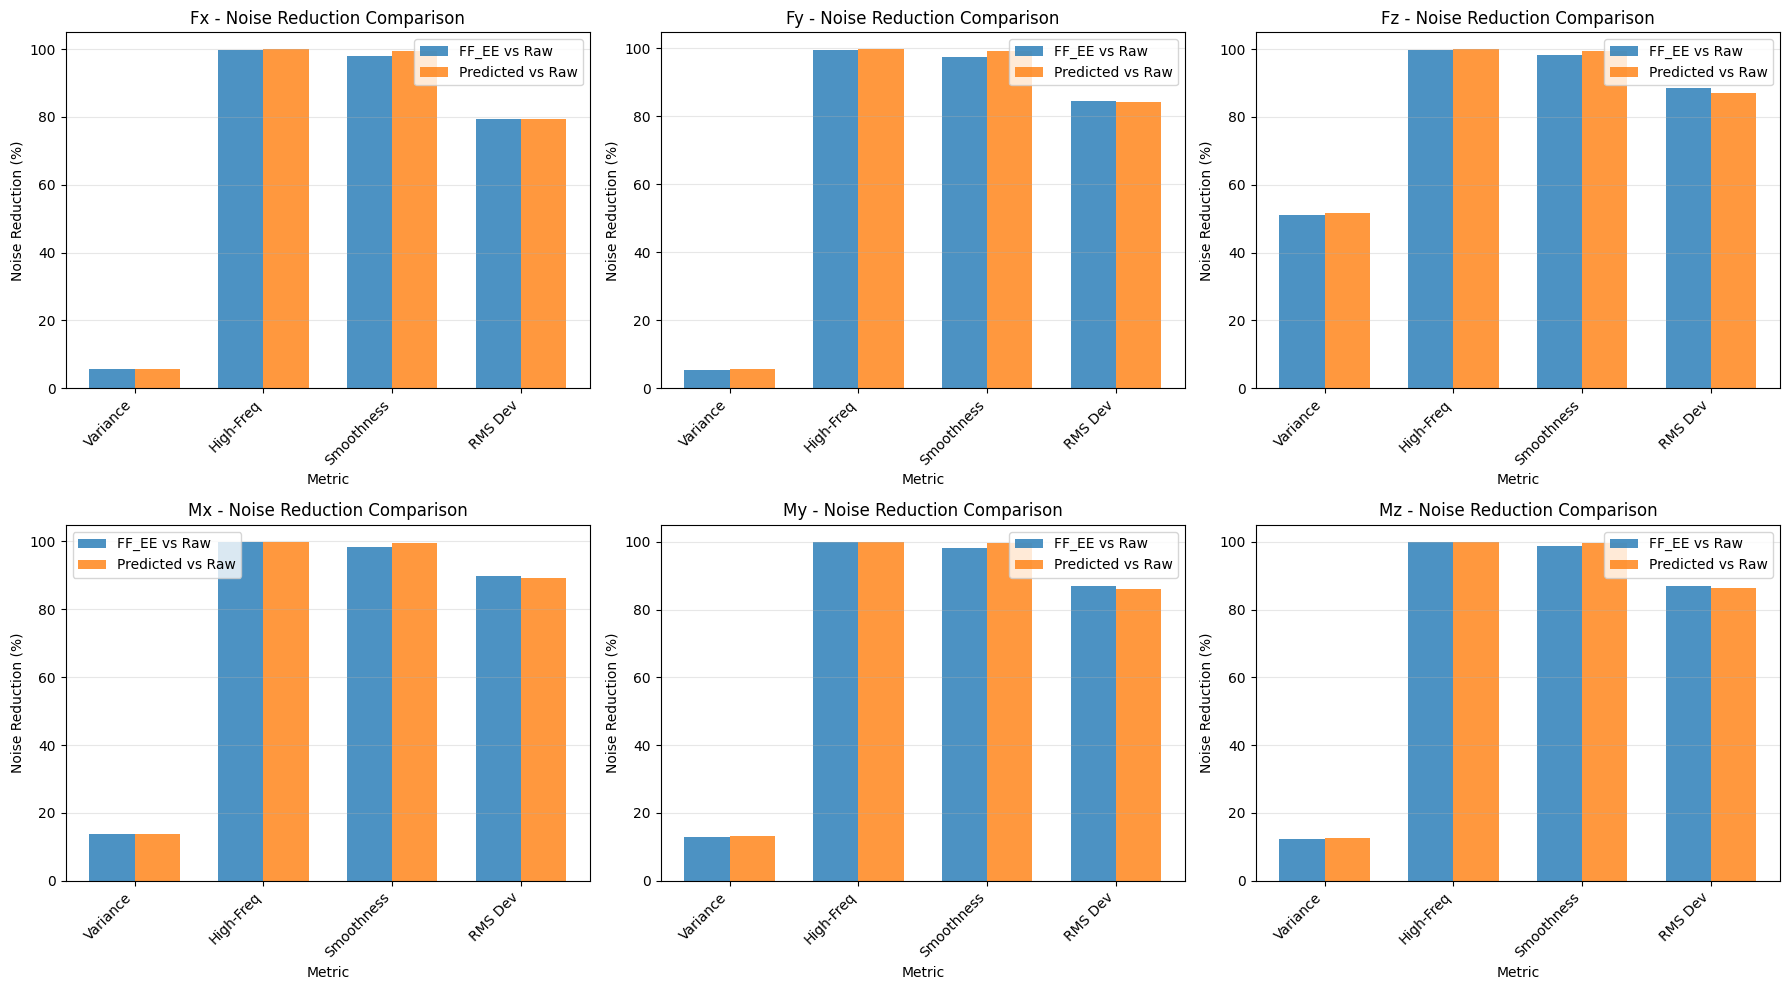

In [7]:
# Visualizations: Noise Reduction Comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    # Prepare data for bar plot
    metrics = ['Variance', 'High-Freq', 'Smoothness', 'RMS Dev']
    ffee_reductions = [
        variance_df.iloc[dim]['reduction_ffee_%'],
        frequency_df.iloc[dim]['reduction_ffee_%'],
        smoothness_df.iloc[dim]['reduction_ffee_%'],
        rms_deviation_df.iloc[dim]['reduction_ffee_%']
    ]
    pred_reductions = [
        variance_df.iloc[dim]['reduction_pred_%'],
        frequency_df.iloc[dim]['reduction_pred_%'],
        smoothness_df.iloc[dim]['reduction_pred_%'],
        rms_deviation_df.iloc[dim]['reduction_pred_%']
    ]
    
    x = np.arange(len(metrics))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, ffee_reductions, width, label='FF_EE vs Raw', alpha=0.8)
    bars2 = ax.bar(x + width/2, pred_reductions, width, label='Predicted vs Raw', alpha=0.8)
    
    ax.set_xlabel('Metric')
    ax.set_ylabel('Noise Reduction (%)')
    ax.set_title(f'{dim_names[dim]} - Noise Reduction Comparison')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()


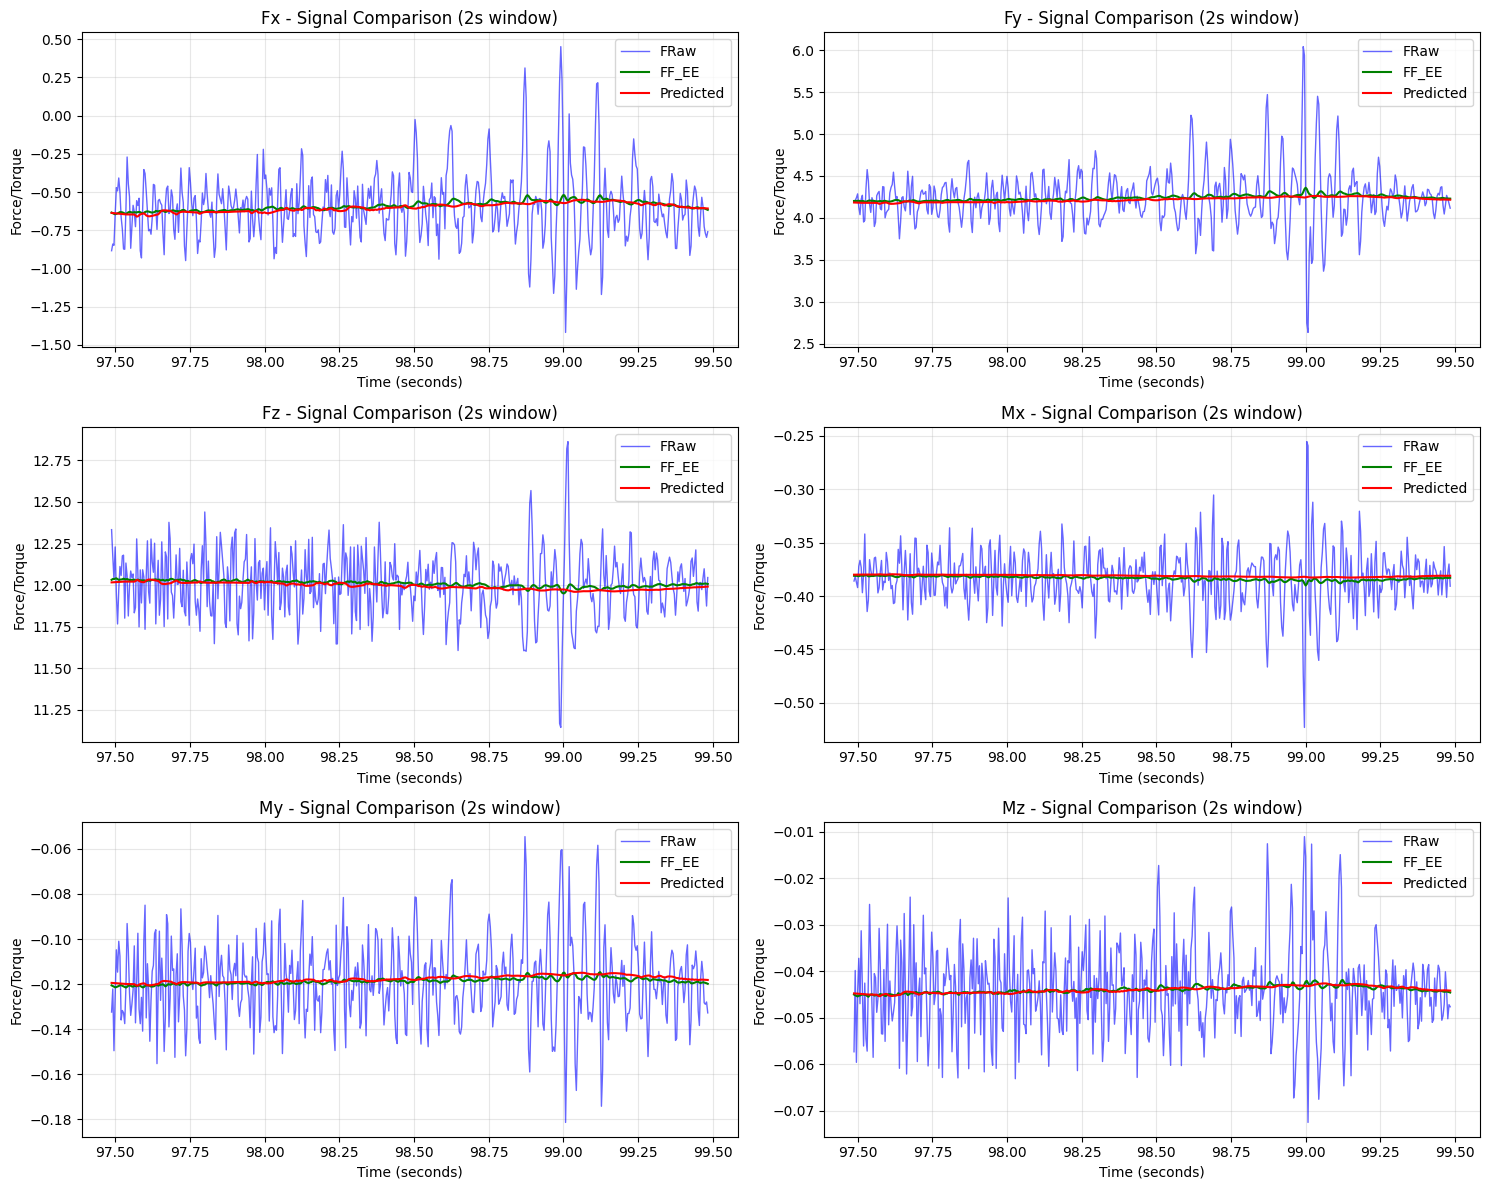

In [8]:
# Visualization: Time series comparison for a sample window
time_window_seconds = 2
time_window_samples = int(time_window_seconds * mean_freq)
start_idx = len(FRaw) // 2  # Start from middle of dataset
end_idx = start_idx + time_window_samples

time_axis = np.arange(start_idx, end_idx) / mean_freq

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    ax.plot(time_axis, FRaw[start_idx:end_idx, dim], 'b-', linewidth=1, alpha=0.6, label='FRaw')
    ax.plot(time_axis, FF_EE[start_idx:end_idx, dim], 'g-', linewidth=1.5, label='FF_EE')
    ax.plot(time_axis, predicted_force[start_idx:end_idx, dim], 'r-', linewidth=1.5, label='Predicted')
    
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Force/Torque')
    ax.set_title(f'{dim_names[dim]} - Signal Comparison ({time_window_seconds}s window)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


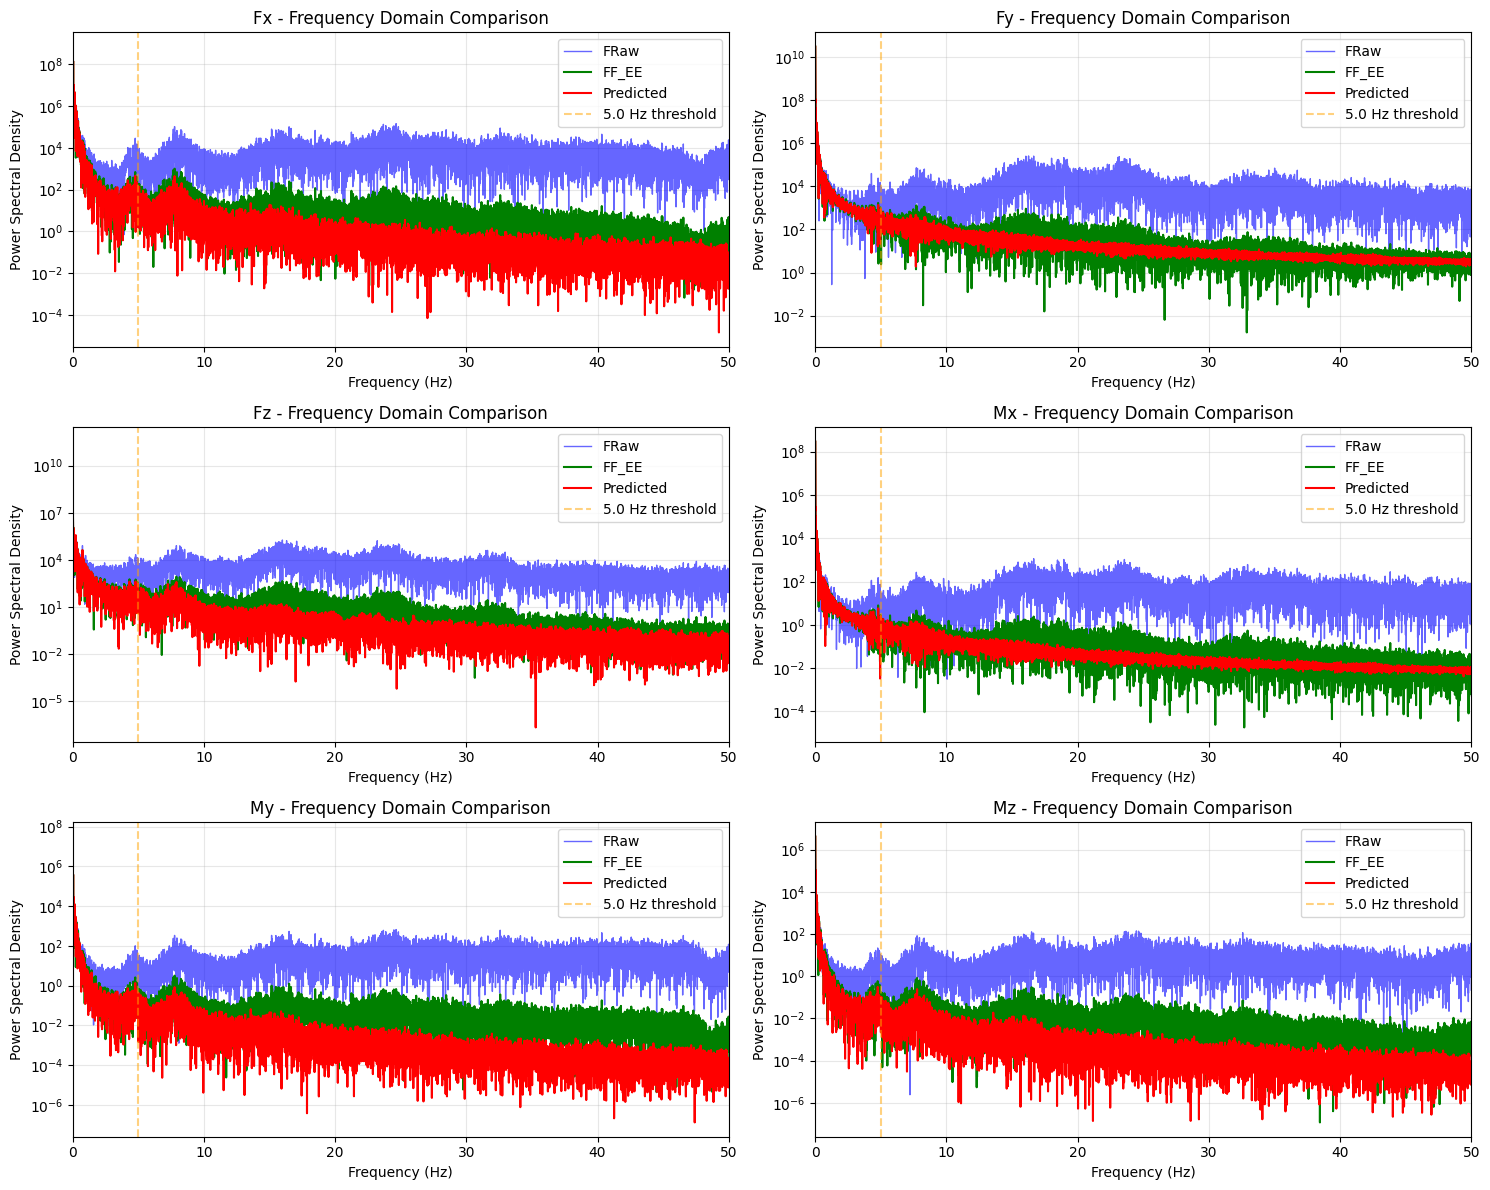

In [9]:
# Visualization: Frequency domain comparison (FFT)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

# Frequency axis for plotting (only positive frequencies)
freqs_plot = np.fft.fftfreq(len(FRaw), 1/mean_freq)
freqs_plot = freqs_plot[:len(freqs_plot)//2]
max_freq_plot = 50  # Show up to 50 Hz

for dim in range(6):
    ax = axes[dim]
    
    # Compute FFT
    fft_raw = np.fft.fft(FRaw[:, dim])
    fft_ffee = np.fft.fft(FF_EE[:, dim])
    fft_pred = np.fft.fft(predicted_force[:, dim])
    
    # Power spectral density
    psd_raw = np.abs(fft_raw[:len(freqs_plot)])**2
    psd_ffee = np.abs(fft_ffee[:len(freqs_plot)])**2
    psd_pred = np.abs(fft_pred[:len(freqs_plot)])**2
    
    # Plot only up to max_freq_plot
    mask = freqs_plot <= max_freq_plot
    ax.semilogy(freqs_plot[mask], psd_raw[mask], 'b-', linewidth=1, alpha=0.6, label='FRaw')
    ax.semilogy(freqs_plot[mask], psd_ffee[mask], 'g-', linewidth=1.5, label='FF_EE')
    ax.semilogy(freqs_plot[mask], psd_pred[mask], 'r-', linewidth=1.5, label='Predicted')
    
    ax.axvline(x=high_freq_threshold, color='orange', linestyle='--', alpha=0.5, label=f'{high_freq_threshold} Hz threshold')
    
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power Spectral Density')
    ax.set_title(f'{dim_names[dim]} - Frequency Domain Comparison')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, max_freq_plot)

plt.tight_layout()
plt.show()


In [10]:
# Export summary results to a readable format
print("\n" + "=" * 80)
print("EXPORTING SUMMARY RESULTS")
print("=" * 80)

# Create a comprehensive summary
summary_report = {
    'analysis_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'total_samples': len(data_points),
    'sampling_frequency_hz': mean_freq,
    'high_frequency_threshold_hz': high_freq_threshold,
    'smoothing_window_size': window_size,
    'per_dimension_results': []
}

for dim in range(6):
    summary_report['per_dimension_results'].append({
        'dimension': dim_names[dim],
        'variance_reduction': {
            'ffee_vs_raw_%': float(variance_df.iloc[dim]['reduction_ffee_%']),
            'predicted_vs_raw_%': float(variance_df.iloc[dim]['reduction_pred_%'])
        },
        'high_frequency_reduction': {
            'ffee_vs_raw_%': float(frequency_df.iloc[dim]['reduction_ffee_%']),
            'predicted_vs_raw_%': float(frequency_df.iloc[dim]['reduction_pred_%'])
        },
        'smoothness_improvement': {
            'ffee_vs_raw_%': float(smoothness_df.iloc[dim]['reduction_ffee_%']),
            'predicted_vs_raw_%': float(smoothness_df.iloc[dim]['reduction_pred_%'])
        },
        'rms_deviation_reduction': {
            'ffee_vs_raw_%': float(rms_deviation_df.iloc[dim]['reduction_ffee_%']),
            'predicted_vs_raw_%': float(rms_deviation_df.iloc[dim]['reduction_pred_%'])
        }
    })

# Save to JSON
output_json = Path('noise_reduction_summary.json')
with open(output_json, 'w') as f:
    json.dump(summary_report, f, indent=2)

print(f"✓ Summary saved to {output_json}")
print(f"\nKey Findings:")
print(f"  Average variance reduction - FF_EE: {variance_df['reduction_ffee_%'].mean():.2f}%")
print(f"  Average variance reduction - Predicted: {variance_df['reduction_pred_%'].mean():.2f}%")
print(f"  Average high-freq reduction - FF_EE: {frequency_df['reduction_ffee_%'].mean():.2f}%")
print(f"  Average high-freq reduction - Predicted: {frequency_df['reduction_pred_%'].mean():.2f}%")



EXPORTING SUMMARY RESULTS
✓ Summary saved to noise_reduction_summary.json

Key Findings:
  Average variance reduction - FF_EE: 16.91%
  Average variance reduction - Predicted: 17.07%
  Average high-freq reduction - FF_EE: 99.80%
  Average high-freq reduction - Predicted: 99.92%
